In [1]:
import os 
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

### Thuật toán
- Tiếp cận dưới góc nhìn bài toán Regression. Tập trung vào feature engineering and data preprocessing
#### Training
- Xây dựng mô hình ML cho từng kho đến 1A (không phải từng cặp - lý do: hiệu suất ko thay đổi khi làm cho từng cặp)
- Thu thập dữ liệu: Thu thập theo hành trình (trajectory) của đơn. Mỗi một lần đơn check in, out tại một kho cho ta một điểm dữ liệu (kho nhiều IN OUT thì lấy first IN và last OUT): IO status (IN, OUT), tại kho nào (warehouse), thời gian nào (t0), thời gian đến kho 1A như thế nào so với t0 (offset time: thời gian thực + 24h nếu là ngày hôm sau so sánh với thời điểm t0).
- Ưu điểm: Cho ta nhiều điểm dữ liệu hơn và cũng phù hợp vì ta sẽ phải dự đoán thời điểm đến 1A dựa vào trạng thái của đơn (có thể đơn đang ở bước trung gian tại một kho nào đó)
- INPUT: gồm nhiều đặc trưng từ kho gửi (vị trí, thời gian) và các thông tin về bill (ví dụ: VD_type,...), có làm thêm về feature engineering.
- OUTPUT: offset time.
- Chuyển hoàn toàn về bài toán Regresion dùng LightGBM (phù hợp với bài toán có đặc trưng liên tục và rời rạc: catergogical).
- Vận hành thực tế dữ liệu có thể bị thiếu: Huấn luyện mô hình cả với trường hợp này.
#### Testing
- Dữ liệu chia thành train và test, lấy một mốc thời gian T. Train toàn bộ dữ liệu trước T, kiểm thử test cho thời điểm sau T.
- Chọn một mốc thời gian: Ví dụ 21h. Tại mỗi ngày xét tất cả các đơn phát sinh trước 21h của ngày hôm đó và chưa đến kho 1A. Thu thập trạng thái gần nhất của đơn (IO status, time, location). Dự báo thời gian đến kho 1A. Cách làm này sát với mô phỏng thực tế.
- Kiểm thử cho kết quả khả quan. Mô hình gặp khó ở các Kho bất thường (do thiếu thông tin bill hoặc dữ liệu ít).
- MAE: 3.0303 hours, MedAE : 1.4872 hours, R2: 0.4464)
#### Inference (vận hành thực tế)

In [2]:
selected_set = {'Kho Sóng Thần'}
# selected_set = {'Kho Văn Giang'}

### Đọc và lọc dữ liệu

In [3]:
OUTPUT_DIR = "output"

wh1a = pd.read_csv('/data/hoan/proj26/NhatTin-route-recognition/data/warehouse_1A.csv') 
set_1a = set(wh1a['name'].dropna().str.strip()) 
bill = pd.read_csv('/data/hoan/proj26/NhatTin-route-recognition/data/bill.csv', usecols = ['bill_code', 'actual_weight'])

In [4]:
bill.head(2)

,bill_code,actual_weight
0,B_0000000,31.0
1,B_0000001,31.0


In [5]:
bill.shape

(2547967, 2)

In [6]:
chunks = [] 
for chunk in pd.read_csv('/data/hoan/proj26/NhatTin-route-recognition/data/bill_schedule.csv',chunksize = 500_000):
    chunk['io_time'] = pd.to_datetime(chunk['io_time']) 
    chunks.append(chunk) 

sche_full = pd.concat(chunks, ignore_index=True) 
del chunks 
sche_full = sche_full.sort_values(['bill_code', 'io_time']).reset_index(drop=True)

In [7]:
sche_full.shape

(16037812, 5)

In [8]:
chunks = [] 
for chunk in pd.read_csv('/data/hoan/proj26/NhatTin-route-recognition/data/bill_schedule.csv',chunksize = 500_000):
    chunk['io_time'] = pd.to_datetime(chunk['io_time']) 
    chunks.append(chunk) 

sche = pd.concat(chunks, ignore_index=True) 
del chunks 
sche = sche.sort_values(['bill_code', 'io_time']).reset_index(drop=True) 


sche['pre_wh'] = sche.groupby('bill_code')['warehouse_name'].shift(1) 
sche['next_wh'] = sche.groupby('bill_code')['warehouse_name'].shift(-1) 

sche_first = sche[sche['warehouse_name'] != sche['pre_wh']].copy() 
sche_last = sche[sche['warehouse_name'] != sche['next_wh']].copy() 

sche_first['wh_rank'] = sche_first.groupby('bill_code').cumcount() 
sche_last['wh_rank'] = sche_last.groupby('bill_code').cumcount() 

sche_1a = sche_first[sche_first['warehouse_name'].isin(set_1a)] 
count_1a = sche_1a.groupby('bill_code').size().reset_index(name = 'count_1a') 
count_1a = count_1a[count_1a['count_1a'] >= 2] 
valid_bills = set(count_1a['bill_code'])

sche_first = sche_first[sche_first['bill_code'].isin(valid_bills)]
max_rank_first = sche_first.groupby('bill_code')['wh_rank'].transform('max') 
sche_first['wh_rank_rev'] = max_rank_first - sche_first['wh_rank'] 
sche_first = sche_first.merge(bill, on = 'bill_code', how = 'inner')

sche_last = sche_last[sche_last['bill_code'].isin(valid_bills)]
max_rank_last = sche_last.groupby('bill_code')['wh_rank'].transform('max') 
sche_last['wh_rank_rev'] = max_rank_last - sche_last['wh_rank'] 
sche_last = sche_last.merge(bill, on = 'bill_code', how = 'inner')

In [9]:
sche_final = pd.concat([sche_first, sche_last], ignore_index=True)

In [10]:
sche_final = sche_final.sort_values(
    ['bill_code', 'io_time']
).reset_index(drop=True)

In [11]:
sche_final.iloc[18:,:].head(2)

,bill_code,io_status,io_time,warehouse_name,warehouse_code,pre_wh,next_wh,wh_rank,wh_rank_rev,actual_weight
18,B_0000002,IN,2026-01-03 16:26:08,Kho Chương Mỹ,W_0000110,NaN,Kho Chương Mỹ,0,4,70.0
19,B_0000002,OUT,2026-01-03 16:26:44,Kho Chương Mỹ,W_0000110,Kho Chương Mỹ,Kho Văn Giang,0,4,70.0


In [12]:
sche.head(2)

,bill_code,io_status,io_time,warehouse_name,warehouse_code,pre_wh,next_wh
0,B_0000000,IN,2025-12-30 10:06:30,Kho Văn Giang,W_0000107,NaN,Kho Văn Giang
1,B_0000000,OUT,2026-01-02 13:11:16,Kho Văn Giang,W_0000107,Kho Văn Giang,Kho Thanh Hóa


In [13]:
### Chỉ lấy bills phải đi qua một kho 1A nào đó.
valid_bills = sche.loc[
    sche['warehouse_name'].isin(selected_set),
    'bill_code'
].unique()

sche_filtered = sche[sche['bill_code'].isin(valid_bills)].copy()

In [14]:
# sche_filtered

In [15]:
### Xóa bỏ hết dòng dữ liệu sau khi kho 1A được chọn (selected_set) xuất hiện

# keep rows only up to (and including) the first occurrence of a warehouse in selected_set for each bill_code
# Position of each row within a bill
sche['row_id'] = sche.groupby('bill_code').cumcount()

# Position of the first selected warehouse for each bill
first_selected = (
    sche[sche['warehouse_name'].isin(selected_set)]
    .groupby('bill_code')['row_id']
    .min()
    .rename('first_selected_row')
)

# Join back to all rows
sche = sche.merge(first_selected, on='bill_code', how='left')

# Keep rows up to and including the first selected warehouse
sche_filtered = sche[
    sche['row_id'] <= sche['first_selected_row']
].copy()

# Clean up
sche_filtered = sche_filtered.drop(columns=['row_id', 'first_selected_row'])

In [16]:
sche_filtered.head(2)

,bill_code,io_status,io_time,warehouse_name,warehouse_code,pre_wh,next_wh
141,B_0000013,OUT,2026-01-17 20:13:28,Kho Nam Từ Liêm,W_0000082,NaN,Kho Văn Giang
142,B_0000013,IN,2026-01-18 04:01:06,Kho Văn Giang,W_0000107,Kho Nam Từ Liêm,Kho Văn Giang


In [17]:
## Chỉ giữ các bills đến Văn Giang đầu tiên và chưa qua kho 1A nào
set_1a_without_selected_set = set_1a - selected_set


# Bills that visit any warehouse in set_1a
bills_to_remove = sche_filtered.loc[
    sche_filtered['warehouse_name'].isin(set_1a_without_selected_set),
    'bill_code'
].unique()

# Remove those bills entirely
sche_filtered = sche_filtered[
    ~sche_filtered['bill_code'].isin(bills_to_remove)
].copy()

In [18]:
sche_filtered

,bill_code,io_status,io_time,warehouse_name,warehouse_code,pre_wh,next_wh
194,B_0000018,OUT,2026-01-21 04:59:03,Kho Long An,W_0000313,NaN,Kho Sóng Thần
195,B_0000018,IN,2026-01-21 08:55:09,Kho Sóng Thần,W_0000269,Kho Long An,Kho Sóng Thần
209,B_0000020,OUT,2026-01-21 21:15:31,Kho Long An,W_0000313,NaN,Kho Sóng Thần
210,B_0000020,OUT,2026-01-22 14:18:22,Kho Sóng Thần,W_0000269,Kho Long An,Kho Văn Giang
316,B_0000029,OUT,2026-01-29 21:01:41,Kho Long An,W_0000313,NaN,Kho Sóng Thần
...,...,...,...,...,...,...,...
16037762,B_2547957,OUT,2026-05-28 20:01:04,Kho Dự án Bình Dương,W_0000310,NaN,Kho Sóng Thần
16037763,B_2547957,IN,2026-05-28 21:24:15,Kho Sóng Thần,W_0000269,Kho Dự án Bình Dương,Kho Sóng Thần
16037778,B_2547960,IN,2026-05-28 18:16:12,Kho Đà Lạt - Lâm Đồng,W_0000185,NaN,Kho Đà Lạt - Lâm Đồng
16037779,B_2547960,OUT,2026-05-28 18:19:38,Kho Đà Lạt - Lâm Đồng,W_0000185,Kho Đà Lạt - Lâm Đồng,Kho Sóng Thần


In [19]:
# Which bills likely traveled together?
# What trip did they follow before arriving?
# Which trip patterns occur repeatedly?

In [20]:
import pandas as pd

sche = sche_filtered.sort_values(["bill_code", "io_time"]).copy()

### Chọn hành trình kết thúc tại một kho 1A

In [393]:
trajectory_df = (
    sche.groupby("bill_code")
        .agg({
            "warehouse_name": list,
            "io_status": list,
            "io_time": list
        })
        .reset_index()
)

trajectory_df["trajectory"] = trajectory_df.apply(
    lambda r: list(zip(
        r.warehouse_name,
        r.io_status
    )),
    axis=1
)

In [394]:
trajectory_df.shape

(1182596, 5)

In [396]:
destination = next(iter(selected_set))
destination

'Kho Sóng Thần'

In [397]:
arrival = (
    sche[
        (sche.warehouse_name == destination) &
        (sche.io_status == "IN")
    ]
    .groupby("bill_code")
    .first()["io_time"]
)

trajectory_df["arrival_time"] = trajectory_df.bill_code.map(arrival)

In [398]:
trajectory_df = trajectory_df.dropna(subset=["arrival_time"])

trajectory_df["arrival_sec"] = (
    trajectory_df.arrival_time.astype("int64")
    // 10**9
)

In [399]:
## Lọc lấy lộ trình có độ dài ít nhất là 2
trajectory_df = trajectory_df[
    trajectory_df["io_status"].apply(len) >= 2
].copy() 

In [400]:
trajectory_df.shape

(914395, 7)

In [401]:
trajectory_df["warehouse_2last"] = trajectory_df["warehouse_name"].apply(lambda x: x[-2])

In [402]:
warehouse_len2 = set(trajectory_df["warehouse_2last"])

In [ ]:
warehouse_freq = (
    trajectory_df["warehouse_2last"]
    .value_counts()
    .rename_axis("warehouse_2last")
    .reset_index(name="frequency")
)
# warehouse_freq

In [405]:
trajectory_df_full_target = trajectory_df.copy()

In [404]:
warehouse_freq.head(10)

,warehouse_2last,frequency
0,Kho Digiworld,124167
1,Kho Đồng Nai,74320
2,Kho Amway,65169
3,Kho TGDĐ M14,47073
4,Kho Dự án Bình Dương,43834
5,Kho Bưu Cục Quận 9,31816
6,Kho Long An,24242
7,Kho FTG 3B Nhà Bè,24073
8,Kho Dự án Viettel,23066
9,Kho Bưu Cục Cô Giang,20166


### Chọn bưu cục nguồn (OPTIONAL) - không dùng
- Xem lại code v2 nếu cần

In [660]:
# source = 'Kho Phú Quốc' #'Kho Bưu Cục Quận 9'# 'Kho KHO HƯNG PHÚ' #'Kho Đồng Nai' #'Kho Bưu Cục Cô Giang' #'Kho Bưu Cục Quận 9'
# trajectory_df = trajectory_df_full_target[trajectory_df_full_target.warehouse_2last==source].copy()
trajectory_df = trajectory_df_full_target.copy()

In [661]:
trajectory_df.head(5)

,bill_code,warehouse_name,io_status,io_time,trajectory,arrival_time,arrival_sec,warehouse_2last
0,B_0000018,"[Kho Long An, Kho Sóng Thần]","[OUT, IN]","[2026-01-21 04:59:03, 2026-01-21 08:55:09]","[(Kho Long An, OUT), (Kho Sóng Thần, IN)]",2026-01-21 08:55:09,1768985709,Kho Long An
2,B_0000029,"[Kho Long An, Kho Sóng Thần]","[OUT, IN]","[2026-01-29 21:01:41, 2026-01-30 04:35:00]","[(Kho Long An, OUT), (Kho Sóng Thần, IN)]",2026-01-30 04:35:00,1769747700,Kho Long An
3,B_0000038,"[Kho Đồng Nai, Kho Đồng Nai, Kho Sóng Thần]","[IN, OUT, IN]","[2026-02-03 20:56:58, 2026-02-04 00:33:37, 202...","[(Kho Đồng Nai, IN), (Kho Đồng Nai, OUT), (Kho...",2026-02-04 07:47:02,1770191222,Kho Đồng Nai
4,B_0000040,"[Kho Đồng Nai, Kho Đồng Nai, Kho Sóng Thần]","[IN, OUT, IN]","[2026-02-03 21:17:16, 2026-02-03 21:23:12, 202...","[(Kho Đồng Nai, IN), (Kho Đồng Nai, OUT), (Kho...",2026-02-05 01:20:12,1770254412,Kho Đồng Nai
7,B_0000067,"[Kho Đồng Nai, Kho Đồng Nai, Kho Sóng Thần]","[IN, OUT, IN]","[2026-02-06 18:38:53, 2026-02-06 19:10:56, 202...","[(Kho Đồng Nai, IN), (Kho Đồng Nai, OUT), (Kho...",2026-02-06 21:05:40,1770411940,Kho Đồng Nai


#### Xây dựng đặc trưng tại mỗi hành trình của đơn

In [662]:
### Fast version
import pandas as pd
import numpy as np


def create_stage_features_fast(trajectory_df):

    # ============================================================
    # 1. Select required columns
    # ============================================================
    df = trajectory_df[
        [
            "bill_code",
            "warehouse_name",
            "io_status",
            "io_time",
            "arrival_time"
        ]
    ].copy()

    # ============================================================
    # 2. Convert arrival_time once
    # ============================================================
    df["arrival_time"] = pd.to_datetime(
        df["arrival_time"],
        errors="coerce"
    )

    # ============================================================
    # 3. Remove LAST stage because it is the output
    # ============================================================
    df["warehouse_name"] = df["warehouse_name"].str[:-1]
    df["io_status"] = df["io_status"].str[:-1]
    df["io_time"] = df["io_time"].str[:-1]

    # ============================================================
    # 4. Explode stages explode() converts a column containing lists into multiple rows.
    # ============================================================
    df = df.explode(
        ["warehouse_name", "io_status", "io_time"],
        ignore_index=True
    )

    # Remove empty stages
    df = df.dropna(
        subset=["io_status"]
    )

    # ============================================================
    # 5. Rename source features
    # ============================================================
    df = df.rename(
        columns={
            "warehouse_name": "warehouse_source",
            "io_status": "io_status_source"
        }
    )

    # ============================================================
    # 6. Convert source time to datetime
    # ============================================================
    df["io_time_source_datetime"] = pd.to_datetime(
        df["io_time"],
        errors="coerce"
    )

    # ============================================================
    # 7. Decimal clock hour
    #
    # Example:
    # 22:20:06 -> 22.335
    # ============================================================
    t = df["io_time_source_datetime"]

    df["io_time_source"] = (
        t.dt.hour
        + t.dt.minute / 60
        + t.dt.second / 3600
    )

    # ============================================================
    # 8. Arrival offset from SOURCE DATE MIDNIGHT
    #
    # arrival_time - midnight(source date)
    # ============================================================
    df["arrival_offset_hours"] = (
        df["arrival_time"]
        - df["io_time_source_datetime"].dt.normalize()
    ).dt.total_seconds() / 3600

    # ============================================================
    # 9. Create missing-data version for OUT
    #
    # warehouse stays the same
    # io_status_source = -1
    # io_time_source   = -1
    #
    # Target remains the same
    # ============================================================
    out_rows = df[
        df["io_status_source"].eq("OUT")
    ].copy()

    out_rows["io_status_source"] = -1
    out_rows["io_time_source"] = -1

    # ============================================================
    # 10. Combine normal + missing versions
    # ============================================================
    result = pd.concat(
        [df, out_rows],
        ignore_index=True
    )
    # result = df # Không lấy phiên bản missing làm gì cả

    # ============================================================
    # 11. Keep required columns
    # ============================================================
    result = result[
        [
            "bill_code",
            "warehouse_source",
            "io_status_source",
            "io_time_source",
            "arrival_time",
            "arrival_offset_hours"
        ]
    ]

    return result

In [663]:
# stage_features = create_stage_features(
#     trajectory_df
# )
stage_features = create_stage_features_fast(
    trajectory_df
)

In [664]:
stage_features.shape, stage_features.columns

((2235231, 6),
 Index(['bill_code', 'warehouse_source', 'io_status_source', 'io_time_source',
        'arrival_time', 'arrival_offset_hours'],
       dtype='object'))

In [665]:
stage_features["io_status_source"] = (
    stage_features["io_status_source"].astype(str)
)

In [747]:
stage_features.head(3)

,bill_code,warehouse_source,io_status_source,io_time_source,arrival_time,arrival_offset_hours
0,B_0000018,Kho Long An,OUT,4.984167,2026-01-21 08:55:09,8.919167
1,B_0000029,Kho Long An,OUT,21.028056,2026-01-30 04:35:00,28.583333
2,B_0000038,Kho Đồng Nai,IN,20.949444,2026-02-04 07:47:02,31.783889


In [667]:
import pandas as pd
import numpy as np

df = stage_features.copy()

# ------------------------------------------------------------
# Remove rows with missing values
# ------------------------------------------------------------
df = df.dropna(
    subset=[
        "warehouse_source",
        "io_status_source",
        "io_time_source",
        "arrival_offset_hours"
    ]
).copy()

# ------------------------------------------------------------
# IQR outlier removal within warehouse + IO status
# ------------------------------------------------------------
group_cols = [
    "warehouse_source",
    "io_status_source"
]

Q1 = df.groupby(group_cols)["arrival_offset_hours"].transform("quantile", 0.25)
Q3 = df.groupby(group_cols)["arrival_offset_hours"].transform("quantile", 0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df["is_outlier"] = (
    (df["arrival_offset_hours"] < lower_bound)
    | (df["arrival_offset_hours"] > upper_bound)
)

print("Original rows:", len(df))
print("Outliers:", df["is_outlier"].sum())

stage_features_clean = df[
    ~df["is_outlier"]
].drop(columns="is_outlier").copy()

stage_features_clean = stage_features_clean[stage_features_clean.arrival_offset_hours<=72.0]

print("Remaining rows:", len(stage_features_clean))

Original rows: 2235231
Outliers: 162622
Remaining rows: 2069687


In [668]:
set(stage_features['io_status_source'])

{'-1', 'IN', 'OUT'}

### Note
- arrival_offset_hours: Là giờ đến (clock time) nhưng cộng thêm 24h nếu là ngày hôm sau.
- Từ thời gian arrival_offset_hours quy ra giờ thực thì ta tính mod 24 ra giờ thật. 
- Còn phần nguyên chia cho 24 chính là độ lệch về ngày
- Thêm một phiên bản miss data (-1)

In [670]:
## No OUT info -> Pick the most dominant -> Return the avarage time of the most dominant

### Build ML models

In [674]:
# bill_full = pd.read_csv('/data/hoan/proj26/NhatTin-route-recognition/data/bill.csv')

In [675]:
bill_full_subset = bill_full.merge(
    # stage_features,
    stage_features_clean,
    on="bill_code",
    how="inner"
)

In [676]:
# bill_full_subset = bill_full_subset[bill_full_subset.delivery_navigation_date!='NaT']
bill_full_subset.shape

(2069687, 18)

In [677]:
bill_full_subset.columns

Index(['bill_code', 'VD_type', 'bill_creation_date',
       'delivery_navigation_date', 'receiving_date', 'estimated_delivery_date',
       'actual_delivery_date', 'origin_province', 'origin_district',
       'destination_province', 'destination_district', 'service',
       'actual_weight', 'warehouse_source', 'io_status_source',
       'io_time_source', 'arrival_time', 'arrival_offset_hours'],
      dtype='object')

#### Feature Engineering

In [678]:
import pandas as pd
import numpy as np

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# ============================================================
# 3. Datetime conversion
# ============================================================

bill_full_subset["bill_creation_date"] = pd.to_datetime(
    bill_full_subset["bill_creation_date"],
    errors="coerce"
)

bill_full_subset["estimated_delivery_date"] = pd.to_datetime(
    bill_full_subset["estimated_delivery_date"],
    errors="coerce"
)


# ============================================================
# 4. Feature engineering
# ============================================================

df = bill_full_subset.copy()


# ------------------------------------------------------------
# 4.1 Bill creation date
# ------------------------------------------------------------

df["creation_hour"] = (
    df["bill_creation_date"].dt.hour
    + df["bill_creation_date"].dt.minute / 60
    + df["bill_creation_date"].dt.second / 3600
)

df["creation_day_of_week"] = (
    df["bill_creation_date"].dt.dayofweek
)

df["creation_day_of_month"] = (
    df["bill_creation_date"].dt.day
)

df["creation_month"] = (
    df["bill_creation_date"].dt.month
)

df["creation_week_of_year"] = (
    df["bill_creation_date"]
    .dt.isocalendar()
    .week
    .astype("float")
)

df["creation_day_of_year"] = (
    df["bill_creation_date"].dt.dayofyear
)

df["creation_weekend"] = (
    df["creation_day_of_week"] >= 5
).astype(int)


# ------------------------------------------------------------
# 4.2 Estimated delivery date
# ------------------------------------------------------------

df["estimated_day_of_week"] = (
    df["estimated_delivery_date"].dt.dayofweek
)

df["estimated_day_of_month"] = (
    df["estimated_delivery_date"].dt.day
)

df["estimated_month"] = (
    df["estimated_delivery_date"].dt.month
)

df["estimated_week_of_year"] = (
    df["estimated_delivery_date"]
    .dt.isocalendar()
    .week
    .astype("float")
)

df["estimated_day_of_year"] = (
    df["estimated_delivery_date"].dt.dayofyear
)

df["estimated_weekend"] = (
    df["estimated_day_of_week"] >= 5
).astype(int)


# ------------------------------------------------------------
# 4.3 Estimated delivery duration
# ------------------------------------------------------------

df["estimated_delivery_days"] = (
    df["estimated_delivery_date"]
    - df["bill_creation_date"]
).dt.total_seconds() / (24 * 3600)


# Useful categorical version
df["estimated_delivery_days_cat"] = pd.cut(
    df["estimated_delivery_days"],
    bins=[
        -np.inf,
        0,
        1,
        2,
        3,
        5,
        7,
        14,
        np.inf
    ],
    labels=[
        "<=0",
        "0-1",
        "1-2",
        "2-3",
        "3-5",
        "5-7",
        "7-14",
        ">14"
    ]
)


# ------------------------------------------------------------
# 4.4 Relationship between creation and delivery dates
# ------------------------------------------------------------

df["creation_delivery_dow_diff"] = (
    df["estimated_day_of_week"]
    - df["creation_day_of_week"]
)

df["creation_delivery_dow_diff_circular"] = (
    df["estimated_day_of_week"]
    - df["creation_day_of_week"]
) % 7

df["same_creation_delivery_dow"] = (
    df["creation_day_of_week"]
    == df["estimated_day_of_week"]
).astype(int)

df["same_creation_delivery_month"] = (
    df["creation_month"]
    == df["estimated_month"]
).astype(int)


# ------------------------------------------------------------
# 4.5 Cyclic time features
# ------------------------------------------------------------
# Useful because Monday and Sunday, or 23:00 and 00:00,
# are naturally close in time.

# Creation hour
df["creation_hour_sin"] = np.sin(
    2 * np.pi * df["creation_hour"] / 24
)

df["creation_hour_cos"] = np.cos(
    2 * np.pi * df["creation_hour"] / 24
)

# Creation day of week
df["creation_dow_sin"] = np.sin(
    2 * np.pi * df["creation_day_of_week"] / 7
)

df["creation_dow_cos"] = np.cos(
    2 * np.pi * df["creation_day_of_week"] / 7
)

# Creation month
df["creation_month_sin"] = np.sin(
    2 * np.pi * df["creation_month"] / 12
)

df["creation_month_cos"] = np.cos(
    2 * np.pi * df["creation_month"] / 12
)


# ============================================================
# 5. Route features
# ============================================================

# # Same province
# df["same_province"] = (
#     df["origin_province"]
#     == df["destination_province"]
# ).astype(int)


# # Same district
# df["same_district"] = (
#     (df["origin_province"] == df["destination_province"])
#     &
#     (df["origin_district"] == df["destination_district"])
# ).astype(int)


# Province-level route
df["province_route"] = (
    df["origin_province"].astype(str)
    + " -> "
    + df["destination_province"].astype(str)
)


# District-level route
df["district_route"] = (
    df["origin_district"].astype(str)
    + " -> "
    + df["destination_district"].astype(str)
)


# Full route
df["full_route"] = (
    df["origin_province"].astype(str)
    + "_"
    + df["origin_district"].astype(str)
    + " -> "
    + df["destination_province"].astype(str)
    + "_"
    + df["destination_district"].astype(str)
)


# ============================================================
# 6. Weight features
# ============================================================

df["actual_weight"] = pd.to_numeric(
    df["actual_weight"],
    errors="coerce"
)

# Protect against negative values
df["actual_weight"] = df["actual_weight"].clip(lower=0)

# Log transformation
df["log_actual_weight"] = np.log1p(
    df["actual_weight"]
)


# Weight categories
df["weight_bin"] = pd.cut(
    df["actual_weight"],
    bins=[
        -np.inf,
        0.5,
        1,
        2,
        5,
        10,
        20,
        50,
        np.inf
    ],
    labels=[
        "<=0.5",
        "0.5-1",
        "1-2",
        "2-5",
        "5-10",
        "10-20",
        "20-50",
        ">50"
    ]
)


# ============================================================
# 7. Categorical interaction features
# ============================================================

# Service × VD type
df["service_VD_type"] = (
    df["service"].astype(str)
    + "_"
    + df["VD_type"].astype(str)
)


# Service × creation weekday
df["service_creation_dow"] = (
    df["service"].astype(str)
    + "_"
    + df["creation_day_of_week"].astype(str)
)


# Service × creation hour
df["service_creation_hour"] = (
    df["service"].astype(str)
    + "_"
    + df["creation_hour"].round().astype(str)
)


# VD type × creation weekday
df["VD_type_creation_dow"] = (
    df["VD_type"].astype(str)
    + "_"
    + df["creation_day_of_week"].astype(str)
)


# Route × service
df["route_service"] = (
    df["province_route"].astype(str)
    + "_"
    + df["service"].astype(str)
)


# Route × VD type
df["route_VD_type"] = (
    df["province_route"].astype(str)
    + "_"
    + df["VD_type"].astype(str)
)


# ============================================================
# 8. Sort chronologically
# ============================================================

df = df.sort_values(
    "arrival_time"
).reset_index(drop=True)


# ============================================================
# 9. Remove rows with missing target
# ============================================================

df = df.dropna(
    subset=["arrival_offset_hours"]
).copy()


# ============================================================
# 10. Chronological 80/20 split
# ============================================================

split_idx = int(len(df) * 0.9)

train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()


print("======================================")
print("Dataset")
print("======================================")

print("Total :", len(df))
print("Train :", len(train))
print("Test  :", len(test))

print()

print(
    "Train period:",
    train["bill_creation_date"].min(),
    "->",
    train["bill_creation_date"].max()
)

print(
    "Test period :",
    test["bill_creation_date"].min(),
    "->",
    test["bill_creation_date"].max()
)

Dataset
Total : 2069687
Train : 1862718
Test  : 206969

Train period: 2023-05-26 00:00:00 -> 2068-03-01 00:00:00
Test period : 2023-05-26 00:00:00 -> 2026-05-30 00:00:00


#### Build the Regression model

In [761]:
# ============================================================
# 12. Define features
# ============================================================

# 'warehouse_source', 'io_status_source', 'io_time_source',
#         'arrival_time', 'arrival_offset_hours'

feature_cols = [
    'warehouse_source', 'io_status_source', 'io_time_source',
    # -------------------------
    # Basic categorical
    # -------------------------
    "VD_type",
    "origin_province",
    "origin_district",
    "destination_province",
    "destination_district",
    "service",

    # -------------------------
    # Creation time
    # -------------------------
    "creation_hour",
    "creation_day_of_week",
    "creation_day_of_month",
    "creation_month",
    "creation_week_of_year",
    "creation_day_of_year",
    "creation_weekend",

    # -------------------------
    # Estimated delivery
    # -------------------------
    "estimated_day_of_week",
    "estimated_day_of_month",
    "estimated_month",
    "estimated_week_of_year",
    "estimated_day_of_year",
    "estimated_weekend",

    "estimated_delivery_days",
    "estimated_delivery_days_cat",

    # -------------------------
    # Date relationships
    # -------------------------
    "creation_delivery_dow_diff",
    "creation_delivery_dow_diff_circular",
    "same_creation_delivery_dow",
    "same_creation_delivery_month",

    # -------------------------
    # Cyclic features
    # -------------------------
    "creation_hour_sin",
    "creation_hour_cos",
    "creation_dow_sin",
    "creation_dow_cos",
    "creation_month_sin",
    "creation_month_cos",

    # -------------------------
    # Route
    # -------------------------
    # "same_province",
    # "same_district",
    "province_route",
    "district_route",
    "full_route",

    # -------------------------
    # Weight
    # -------------------------
    "actual_weight",
    "log_actual_weight",
    "weight_bin",

    # -------------------------
    # Interactions
    # -------------------------
    "service_VD_type",
    "service_creation_dow",
    "service_creation_hour",
    "VD_type_creation_dow",
    "route_service",
    "route_VD_type",
]

# ============================================================
# 13. Categorical features
# ============================================================

categorical_features = [
    "warehouse_source",
    "io_status_source",

    "VD_type",
    "origin_province",
    "origin_district",
    "destination_province",
    "destination_district",
    "service",

    "estimated_delivery_days_cat",

    "province_route",
    "district_route",
    "full_route",
    "weight_bin",

    "service_VD_type",
    "service_creation_dow",
    "service_creation_hour",
    "VD_type_creation_dow",
    "route_service",
    "route_VD_type"
]

# Make categorical variables compatible between train/test
for col in categorical_features:

    train[col] = train[col].astype("category")

    test[col] = pd.Categorical(
        test[col],
        categories=train[col].cat.categories
    )

from lightgbm import LGBMRegressor

X_train = train[feature_cols]
y_train = train["arrival_offset_hours"]

X_test = test[feature_cols]
y_test = test["arrival_offset_hours"]


model = LGBMRegressor(
    objective="regression",

    n_estimators=1000,
    learning_rate=0.03,

    num_leaves=31,
    max_depth=-1,

    min_child_samples=20,

    subsample=0.8,
    colsample_bytree=0.8,

    random_state=42,
    n_jobs=-1
)


model.fit(
    X_train,
    y_train,
    categorical_feature=categorical_features
)

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.223031 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27314
[LightGBM] [Info] Number of data points in the train set: 1862718, number of used features: 46
[LightGBM] [Info] Start training from score 24.537563


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.03
,n_estimators,1000
,subsample_for_bin,200000
,objective,'regression'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [768]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "feature": feature_cols,

    "gain": model.booster_.feature_importance(
        importance_type="gain"
    ),

    "split": model.booster_.feature_importance(
        importance_type="split"
    )
})

feature_importance["gain_pct"] = (
    feature_importance["gain"]
    / feature_importance["gain"].sum()
    * 100
)

feature_importance = feature_importance.sort_values(
    "gain",
    ascending=False
).reset_index(drop=True)

# print(
#     feature_importance.to_string(index=False)
# )

In [769]:
# feature_importance

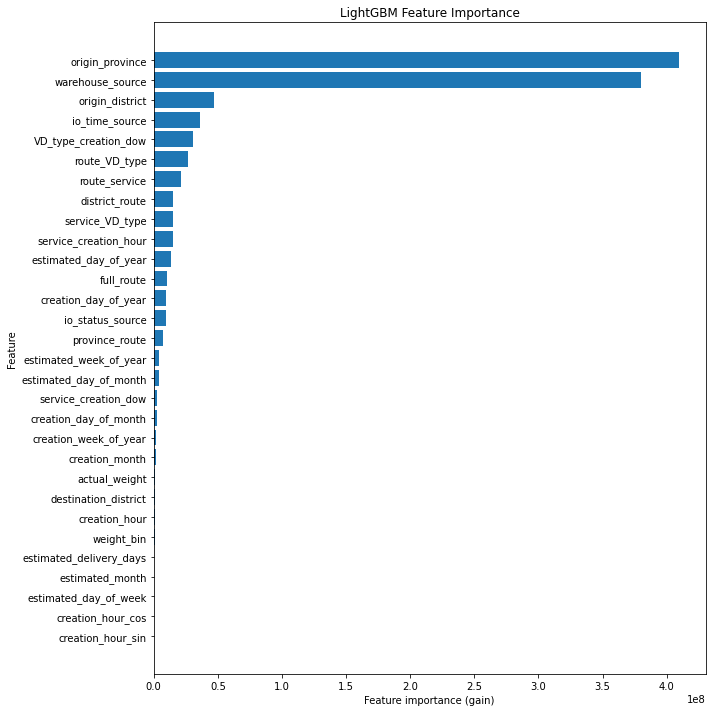

In [770]:
top_n = 30

fi_top = (
    feature_importance
    .head(top_n)
    .sort_values("gain", ascending=True)
)

plt.figure(figsize=(10, 10))

plt.barh(
    fi_top["feature"],
    fi_top["gain"]
)

plt.xlabel("Feature importance (gain)")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")

plt.tight_layout()
plt.show()

In [ ]:
test.head(1)

,bill_code,VD_type,bill_creation_date,delivery_navigation_date,receiving_date,estimated_delivery_date,actual_delivery_date,origin_province,origin_district,destination_province,...,district_route,full_route,log_actual_weight,weight_bin,service_VD_type,service_creation_dow,service_creation_hour,VD_type_creation_dow,route_service,route_VD_type
1862718,B_2266432,BillWebOnline,2026-05-19 17:11:37,NaN,2026-05-20 15:08:51,2026-05-23 17:11:00,2026-05-21 22:58:21,Tp Hồ Chí Minh,Quận Bình Tân,Long An,...,Quận Bình Tân -> Thành phố Tân An,Tp Hồ Chí Minh_Quận Bình Tân -> Long An_Thành ...,3.178054,20-50,Đường bộ_BillWebOnline,Đường bộ_1.0,Đường bộ_17.0,BillWebOnline_1.0,Tp Hồ Chí Minh -> Long An_Đường bộ,Tp Hồ Chí Minh -> Long An_BillWebOnline


In [719]:
import numpy as np

sample_size = 100000
if int(len(test["bill_code"].unique())) >= sample_size:
    random_bill_codes = np.random.choice(
        test["bill_code"].unique(),
        size=sample_size,
        replace=False
    )
    
    test = test[ test["bill_code"].isin(random_bill_codes)
    ].copy()
    trajectory_df_sample = trajectory_df[
        trajectory_df["bill_code"].isin(random_bill_codes)
    ].copy()
else:
    trajectory_df_sample = trajectory_df.copy()

#### Test the model using SNAPSHOT

In [720]:
import gc
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

# ============================================================
# PARAMETERS
# ============================================================

SNAPSHOT_HOUR = 20
SNAPSHOT_MINUTE = 0

CHUNK_SIZE = 5000


# ============================================================
# 0. PREPARE TEST DATA
# ============================================================

test = test.copy()

test["bill_code"] = test["bill_code"].astype(str)

# arrival_time is needed for evaluation
test["arrival_time"] = pd.to_datetime(
    test["arrival_time"],
    errors="coerce"
)

print("Number of test bills:", test["bill_code"].nunique())
print("Valid test arrival_time:", test["arrival_time"].notna().sum())


# ============================================================
# 1. PREPARE TRAJECTORY DATA
# ============================================================

traj = trajectory_df_sample[
    [
        "bill_code",
        "warehouse_name",
        "io_status",
        "io_time",
        "arrival_time"
    ]
].copy()

traj["bill_code"] = traj["bill_code"].astype(str)

# ------------------------------------------------------------
# Keep only test bills
# ------------------------------------------------------------

test_bill_codes = set(
    test["bill_code"].dropna().unique()
)

traj = traj[
    traj["bill_code"].isin(test_bill_codes)
].copy()

print("Trajectory rows before processing:", len(traj))
print("Trajectory bills:", traj["bill_code"].nunique())


# ============================================================
# 2. CONVERT ARRIVAL TIME
# ============================================================

traj["arrival_time"] = pd.to_datetime(
    traj["arrival_time"],
    errors="coerce"
)

print(
    "Valid trajectory arrival_time:",
    traj["arrival_time"].notna().sum()
)


# ============================================================
# 3. REMOVE FINAL STAGE
# ============================================================
#
# The original trajectory contains the final stage.
# We remove the final element from each trajectory so that
# the model does not use information from the final arrival.
#
# Example:
#
# warehouse_name = [A, B, C, D]
#                 -> [A, B, C]
#
# io_status      = [OUT, IN, OUT, IN]
#                 -> [OUT, IN, OUT]
#
# ============================================================

traj["warehouse_name"] = (
    traj["warehouse_name"].str[:-1]
)

traj["io_status"] = (
    traj["io_status"].str[:-1]
)

traj["io_time"] = (
    traj["io_time"].str[:-1]
)


# ============================================================
# 4. EXPLODE TRAJECTORIES
# ============================================================

traj = traj.explode(
    [
        "warehouse_name",
        "io_status",
        "io_time"
    ],
    ignore_index=True
)

# Remove rows with missing trajectory information
traj = traj.dropna(
    subset=[
        "warehouse_name",
        "io_status",
        "io_time"
    ]
).copy()

print("Trajectory rows after explode:", len(traj))


# ============================================================
# 5. CONVERT IO TIME
# ============================================================

traj["io_time"] = pd.to_datetime(
    traj["io_time"],
    errors="coerce"
)

traj = traj.dropna(
    subset=["io_time"]
).copy()

print("Trajectory rows with valid io_time:", len(traj))


# ============================================================
# 6. SORT FOR MERGE_ASOF
# ============================================================

traj = traj.sort_values(
    ["io_time", "bill_code"]
).reset_index(drop=True)

traj = traj[
    [
        "bill_code",
        "warehouse_name",
        "io_status",
        "io_time",
        "arrival_time"
    ]
].copy()


# ============================================================
# 7. DETERMINE EVALUATION DATE RANGE
# ============================================================
#
# IMPORTANT:
#
# We do NOT use:
#   - bill_creation_date
#   - actual_delivery_date
#
# because bill_creation_date contains many NaT values.
#
# Instead:
#   start = first observed trajectory event
#   end   = latest actual arrival
#
# ============================================================

TEST_START_DATE = (
    traj["io_time"]
    .min()
    .normalize()
)

LATEST_DATE = (
    traj["arrival_time"]
    .max()
    .normalize()
)

print()
print("=" * 60)
print("EVALUATION PERIOD")
print("=" * 60)

print("Evaluation start:", TEST_START_DATE)
print("Evaluation end  :", LATEST_DATE)


evaluation_dates = pd.date_range(
    start=TEST_START_DATE,
    end=LATEST_DATE,
    freq="D"
)

snapshot_dates = pd.DataFrame({
    "snapshot_date": evaluation_dates
})

snapshot_dates["snapshot_time"] = (
    snapshot_dates["snapshot_date"]
    + pd.Timedelta(hours=SNAPSHOT_HOUR)
    + pd.Timedelta(minutes=SNAPSHOT_MINUTE)
)

print("Number of evaluation days:", len(snapshot_dates))
print(
    "Snapshot time:",
    f"{SNAPSHOT_HOUR:02d}:{SNAPSHOT_MINUTE:02d}"
)


# ============================================================
# 8. PREPARE BILL-LEVEL FEATURES
# ============================================================

bill_features = test.copy()

bill_features["bill_code"] = (
    bill_features["bill_code"].astype(str)
)

# ------------------------------------------------------------
# One row per bill
# ------------------------------------------------------------

if bill_features["bill_code"].duplicated().any():

    print(
        "WARNING: duplicated bill_code in test. "
        "Keeping last row."
    )

    bill_features = (
        bill_features
        .drop_duplicates(
            "bill_code",
            keep="last"
        )
        .copy()
    )

print(
    "Unique test bills:",
    bill_features["bill_code"].nunique()
)


# ============================================================
# 9. REMOVE DYNAMIC FEATURES
# ============================================================
#
# These will be generated from the current trajectory stage
# at each snapshot.
#
# ============================================================

columns_to_drop = [
    "warehouse_source",
    "io_status_source",
    "io_time_source",
    "arrival_offset_hours",
    "arrival_time"
]

bill_features = bill_features.drop(
    columns=[
        c
        for c in columns_to_drop
        if c in bill_features.columns
    ]
)


# ============================================================
# 10. PREPARE BILL CODE ARRAY
# ============================================================

test_bill_codes_array = (
    bill_features["bill_code"]
    .drop_duplicates()
    .values
)

n_bills = len(test_bill_codes_array)

print("Bills to evaluate:", n_bills)


# ============================================================
# 11. CHUNKED DAILY AS-OF EVALUATION
# ============================================================

all_results = []

print()
print("=" * 60)
print("START CHUNKED DAILY AS-OF EVALUATION")
print("=" * 60)


for start in range(
    0,
    n_bills,
    CHUNK_SIZE
):

    end = min(
        start + CHUNK_SIZE,
        n_bills
    )

    chunk_codes = test_bill_codes_array[
        start:end
    ]

    print()
    print(
        f"Processing bills "
        f"{start:,} - {end:,} "
        f"/ {n_bills:,}"
    )


    # ========================================================
    # 11.1 TRAJECTORY FOR THIS CHUNK
    # ========================================================

    traj_chunk = traj[
        traj["bill_code"].isin(chunk_codes)
    ].copy()

    print(
        "  trajectory rows:",
        len(traj_chunk)
    )

    if len(traj_chunk) == 0:

        print("  No trajectory → skip")

        del traj_chunk
        gc.collect()

        continue


    # ========================================================
    # 11.2 CREATE BILL × EVALUATION-DAY
    # ========================================================

    bill_days = pd.DataFrame({

        "bill_code": np.repeat(
            chunk_codes,
            len(snapshot_dates)
        ),

        "snapshot_date": np.tile(
            snapshot_dates["snapshot_date"].values,
            len(chunk_codes)
        ),

        "snapshot_time": np.tile(
            snapshot_dates["snapshot_time"].values,
            len(chunk_codes)
        )
    })

    print(
        "  bill-day rows:",
        len(bill_days)
    )


    # ========================================================
    # 11.3 SORT FOR MERGE_ASOF
    # ========================================================
    #
    # IMPORTANT:
    # merge_asof requires the merge keys to be globally sorted.
    #
    # ========================================================

    bill_days = bill_days.sort_values(
        ["snapshot_time", "bill_code"]
    ).reset_index(drop=True)

    traj_chunk = traj_chunk.sort_values(
        ["io_time", "bill_code"]
    ).reset_index(drop=True)


    # ========================================================
    # 11.4 AS-OF JOIN
    # ========================================================
    #
    # For every bill at every 21:00 snapshot:
    #
    # find the latest trajectory event
    # where io_time <= snapshot_time
    #
    # ========================================================

    current_stage = pd.merge_asof(
        bill_days,
        traj_chunk,
        by="bill_code",
        left_on="snapshot_time",
        right_on="io_time",
        direction="backward"
    )

    print(
        "  after merge_asof:",
        len(current_stage)
    )


    # ========================================================
    # 11.5 REMOVE BILLS THAT ALREADY ARRIVED
    # ========================================================
    #
    # Keep only:
    #
    # arrival_time > snapshot_time
    #
    # This correctly keeps next-day arrivals.
    #
    # Example:
    #
    # snapshot       = Feb 10 21:00
    # arrival        = Feb 11 07:24
    #
    # -> keep
    #
    # ========================================================

    current_stage = current_stage[
        current_stage["arrival_time"]
        > current_stage["snapshot_time"]
    ].copy()

    print(
        "  after not-arrived filter:",
        len(current_stage)
    )


    # ========================================================
    # 11.6 REMOVE BILLS WITH NO KNOWN STAGE
    # ========================================================
    #
    # If there was no trajectory event before snapshot,
    # merge_asof gives io_time = NaT.
    #
    # ========================================================

    current_stage = current_stage[
        current_stage["io_time"].notna()
    ].copy()

    print(
        "  after known-stage filter:",
        len(current_stage)
    )


    # --------------------------------------------------------
    # If nothing remains, continue
    # --------------------------------------------------------

    if len(current_stage) == 0:

        print("  No valid evaluation rows → skip")

        del (
            traj_chunk,
            bill_days,
            current_stage
        )

        gc.collect()

        continue


    # ========================================================
    # 11.7 CREATE DYNAMIC STAGE FEATURES
    # ========================================================

    current_stage = current_stage.rename(
        columns={
            "warehouse_name": "warehouse_source",
            "io_status": "io_status_source"
        }
    )


    # --------------------------------------------------------
    # Decimal clock hour
    #
    # Example:
    # 22:20:06 -> 22.335
    # --------------------------------------------------------

    t = current_stage["io_time"]

    current_stage["io_time_source"] = (
        t.dt.hour
        + t.dt.minute / 60
        + t.dt.second / 3600
    )


    # ========================================================
    # 11.8 TARGET
    # ========================================================
    #
    # Your original target definition:
    #
    # arrival_time
    #       -
    # midnight of source IO date
    #
    # ========================================================

    current_stage["arrival_offset_hours"] = (
        current_stage["arrival_time"]
        - current_stage["io_time"].dt.normalize()
    ).dt.total_seconds() / 3600


    # ========================================================
    # 11.9 MERGE BILL-LEVEL FEATURES
    # ========================================================

    bill_features_chunk = bill_features[
        bill_features["bill_code"].isin(
            chunk_codes
        )
    ].copy()

    eval_chunk = current_stage.merge(
        bill_features_chunk,
        on="bill_code",
        how="left"
    )


    # print('CHECK .................................................................. REPLACE BY -1')

    # mask_in = eval_chunk["io_status_source"].eq("IN")
    
    # eval_chunk.loc[mask_in, "io_status_source"] = '-1'
    # eval_chunk.loc[mask_in, "io_time_source"] = -1

    # ========================================================
    # 11.10 CATEGORICAL FEATURES
    # ========================================================

    # These two can contain mixed types in the original data
    eval_chunk["io_status_source"] = (
        eval_chunk["io_status_source"]
        .astype(str)
    )

    eval_chunk["warehouse_source"] = (
        eval_chunk["warehouse_source"]
        .astype(str)
    )


    for col in categorical_features:

        if col in eval_chunk.columns:

            eval_chunk[col] = pd.Categorical(
                eval_chunk[col],
                categories=train[col].cat.categories
            )


    # ========================================================
    # 11.11 CHECK FEATURES
    # ========================================================

    missing_features = [
        col
        for col in feature_cols
        if col not in eval_chunk.columns
    ]

    if missing_features:

        raise ValueError(
            f"Missing features: {missing_features}"
        )


    # ========================================================
    # 11.12 PREDICTION
    # ========================================================

    X_chunk = eval_chunk[
        feature_cols
    ]

    eval_chunk["y_pred"] = model.predict(
        X_chunk
    )


    # ========================================================
    # 11.13 KEEP ONLY NECESSARY RESULTS
    # ========================================================

    result_chunk = eval_chunk[
        [
            "bill_code",
            "snapshot_date",
            "snapshot_time",
            "warehouse_source",
            "io_status_source",
            "arrival_offset_hours",
            "y_pred"
        ]
    ].copy()

    all_results.append(
        result_chunk
    )

    print(
        "  predictions:",
        len(result_chunk)
    )


    # ========================================================
    # 11.14 FREE MEMORY
    # ========================================================

    del (
        traj_chunk,
        bill_days,
        current_stage,
        eval_chunk,
        X_chunk,
        result_chunk,
        bill_features_chunk
    )

    gc.collect()


# ============================================================
# 12. COMBINE RESULTS
# ============================================================

if len(all_results) > 0:

    eval_df = pd.concat(
        all_results,
        ignore_index=True
    )

else:

    eval_df = pd.DataFrame(
        columns=[
            "bill_code",
            "snapshot_date",
            "snapshot_time",
            "warehouse_source",
            "io_status_source",
            "arrival_offset_hours",
            "y_pred"
        ]
    )


del all_results
gc.collect()


# ============================================================
# 13. BASIC CHECK
# ============================================================

print()
print("=" * 60)
print("EVALUATION RESULT")
print("=" * 60)

print("Rows:", len(eval_df))

if len(eval_df) > 0:

    print(
        "Bills:",
        eval_df["bill_code"].nunique()
    )

    print(
        "Days:",
        eval_df["snapshot_date"].nunique()
    )

    print(
        "Date range:",
        eval_df["snapshot_date"].min(),
        "→",
        eval_df["snapshot_date"].max()
    )

    print()
    print(eval_df.head())

Number of test bills: 50000
Valid test arrival_time: 118211
Trajectory rows before processing: 50000
Trajectory bills: 50000
Valid trajectory arrival_time: 50000
Trajectory rows after explode: 67047
Trajectory rows with valid io_time: 67047

EVALUATION PERIOD
Evaluation start: 2026-05-13 00:00:00
Evaluation end  : 2026-05-30 00:00:00
Number of evaluation days: 18
Snapshot time: 20:00
Unique test bills: 50000
Bills to evaluate: 50000

START CHUNKED DAILY AS-OF EVALUATION

Processing bills 0 - 5,000 / 50,000
  trajectory rows: 6487
  bill-day rows: 90000
  after merge_asof: 90000
  after not-arrived filter: 3717
  after known-stage filter: 3717
  predictions: 3717

Processing bills 5,000 - 10,000 / 50,000
  trajectory rows: 6763
  bill-day rows: 90000
  after merge_asof: 90000
  after not-arrived filter: 3117
  after known-stage filter: 3117
  predictions: 3117

Processing bills 10,000 - 15,000 / 50,000
  trajectory rows: 6607
  bill-day rows: 90000
  after merge_asof: 90000
  after not-

#### Đánh giá mô hình

In [748]:
# ============================================================
# 14. OVERALL METRICS
# ============================================================

if len(eval_df) > 0:

    y_true = eval_df[
        "arrival_offset_hours"
    ]

    y_pred = eval_df[
        "y_pred"
    ]

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    medae = median_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    print()
    print("=" * 60)
    print("OVERALL METRICS")
    print("=" * 60)

    print(f"MAE   : {mae:.4f} hours")
    print(f"MedAE : {medae:.4f} hours")
    print(f"R2    : {r2:.4f}")


OVERALL METRICS
MAE   : 3.0303 hours
MedAE : 1.4872 hours
R2    : 0.4464


In [749]:
# MedAE (Median Absolute Error) is a statistical metric used to evaluate regression models.
# It measures accuracy by finding the median of all absolute differences between target values and predicted values.
# Because it uses the median instead of the mean, MedAE is highly robust to outliers

In [750]:
# warehouse_metrics.to_csv('warehouse_metrics.csv', encoding="utf-8-sig")

In [751]:
# ============================================================
# METRICS BY WAREHOUSE
# ============================================================

print()
print("=" * 60)
print("METRICS BY WAREHOUSE")
print("=" * 60)

warehouse_metrics = []

for warehouse, group in eval_df.groupby(
    "warehouse_source",
    dropna=False
):

    # Keep only valid prediction/target pairs
    group_valid = group[
        group["arrival_offset_hours"].notna()
        & group["y_pred"].notna()
    ]

    if len(group_valid) == 0:
        continue

    y_true_w = group_valid["arrival_offset_hours"]
    y_pred_w = group_valid["y_pred"]

    warehouse_metrics.append({
        "warehouse_source": warehouse,
        "n": len(group_valid),

        "MAE": mean_absolute_error(
            y_true_w,
            y_pred_w
        ),

        "MedAE": median_absolute_error(
            y_true_w,
            y_pred_w
        ),

        "R2": (
            r2_score(y_true_w, y_pred_w)
            if len(group_valid) > 1
            else np.nan
        )
    })

warehouse_metrics = pd.DataFrame(
    warehouse_metrics
)

warehouse_metrics = warehouse_metrics.sort_values(
    "MAE",
    ascending=True
)

print(
    warehouse_metrics.to_string(
        index=False
    )
)


METRICS BY WAREHOUSE
               warehouse_source    n       MAE     MedAE            R2
                        Kho PSD  315  0.322310  0.242339 -2.046868e-01
                 Dự Án Hộ Chiếu  750  0.368790  0.378502 -2.303485e-01
                     Kho SSEHCM  283  0.498261  0.152531 -1.414261e+00
             Kho Bưu Cục Quận 2  131  0.544099  0.422641 -1.278719e-01
              Kho TGDĐ Bảo Hành   68  0.622457  0.318845 -2.807317e+00
                Kho CPN-Đà Nẵng  260  0.750281  0.497497 -4.577289e-01
             Kho Bưu Cục Ga Huế    8  0.760495  0.708772 -9.116077e+01
             Kho Bưu Cục Quận 7  560  0.809611  0.502278 -2.782089e-01
          Kho Bưu cục Bình Minh    5  0.827780  0.363571 -6.074499e+01
              Kho Mai Thúc Loan   92  0.863071  0.928555 -1.067592e+01
            Kho BC Trần Cao Vân   48  0.926189  1.108089 -5.101399e+01
             Kho Dự Án Swat HCM  854  0.946495  0.410002 -6.889325e-01
                    Kho Bay HCM   34  0.952735  0.60205

In [752]:
# ============================================================
# METRICS BY WAREHOUSE
# ============================================================
#   warehouse_source    n     MAE     RMSE   MedAE        R2
# Kho Bưu Cục Quận 9 3296 2.12614 3.983667 1.56141 -0.113795

In [753]:
warehouse_freq = (
    trajectory_df["warehouse_2last"]
    .value_counts()
    .rename_axis("warehouse_2last")
    .reset_index(name="frequency")
)
# warehouse_freq

In [754]:
'Kho Phú Quốc' in list(warehouse_freq['warehouse_2last'])

True

### Nhận xét và phân tích kết quả (phân tích các Kho có bills đủ lớn)
- Hầu hết các bills sai số ở các địa điểm xa, số lượng bills ít nên thường là bất thường
- Kho Hải Dương, Hà Giang, Kho Tây Sơn, Việt Trì ko thấy đi qua 1A, liệu rằng dữ liệu có vấn đề, Bill thuộc nhóm của TGDD
- Kho Kho Hà Giang có vẻ có vấn đề
- Kho Hòa Khánh đi qua  Kho CPN-Đà Nẵng, liệu đây có phải là 1A rồi...
- Kho Cai Lậy, còn đi qua Kho Tiền Giang, nên thời gian sẽ sai số lớn, sai số tại Kho Tiền Giang là 2.280862
- Kho Phú Quốc khó vì đảo xa. Thời gian giao ko ổn định.
- Kho Đa Séc đi qua Kho Đồng Tháp, Kho Đồng Tháp (tương tự Kho Long An) thời gian ko có quy luật (xem scatter plot dưới)


In [756]:
bill_full_subset[bill_full_subset.warehouse_source=='Kho Đồng Tháp'].head(5) #Kho Hà Giang

,bill_code,VD_type,bill_creation_date,delivery_navigation_date,receiving_date,estimated_delivery_date,actual_delivery_date,origin_province,origin_district,destination_province,destination_district,service,actual_weight,warehouse_source,io_status_source,io_time_source,arrival_time,arrival_offset_hours
183,B_0000312,BillWebOnline,2026-02-24 10:58:49,NaN,2026-02-24 15:54:56,2026-02-28 10:58:00,2026-03-01 12:41:57,Đồng Tháp,Thành phố Cao Lãnh,Tp Hồ Chí Minh,Huyện Cần Giờ,Đường bộ,70.00,Kho Đồng Tháp,IN,13.360833,2026-02-26 16:13:30,40.225000
184,B_0000312,BillWebOnline,2026-02-24 10:58:49,NaN,2026-02-24 15:54:56,2026-02-28 10:58:00,2026-03-01 12:41:57,Đồng Tháp,Thành phố Cao Lãnh,Tp Hồ Chí Minh,Huyện Cần Giờ,Đường bộ,70.00,Kho Đồng Tháp,OUT,13.669444,2026-02-26 16:13:30,40.225000
185,B_0000312,BillWebOnline,2026-02-24 10:58:49,NaN,2026-02-24 15:54:56,2026-02-28 10:58:00,2026-03-01 12:41:57,Đồng Tháp,Thành phố Cao Lãnh,Tp Hồ Chí Minh,Huyện Cần Giờ,Đường bộ,70.00,Kho Đồng Tháp,-1,-1.000000,2026-02-26 16:13:30,40.225000
720,B_0001092,BillImport-BC,NaT,NaN,2026-02-26 11:24:18,2026-02-28 11:24:18,2026-03-01 08:10:12,Đồng Tháp,Thành phố Cao Lãnh,Hà Nội,Quận Long Biên,CPN,0.05,Kho Đồng Tháp,IN,13.503611,2026-02-27 10:49:52,34.831111
721,B_0001092,BillImport-BC,NaT,NaN,2026-02-26 11:24:18,2026-02-28 11:24:18,2026-03-01 08:10:12,Đồng Tháp,Thành phố Cao Lãnh,Hà Nội,Quận Long Biên,CPN,0.05,Kho Đồng Tháp,OUT,13.588056,2026-02-27 10:49:52,34.831111


In [757]:
trajectory_df[trajectory_df.bill_code=='B_0004865']

,bill_code,warehouse_name,io_status,io_time,trajectory,arrival_time,arrival_sec,warehouse_2last
1819,B_0004865,"[Kho Sa Đéc, Kho Sa Đéc, Kho Đồng Tháp, Kho Đồ...","[IN, OUT, IN, OUT, IN]","[2026-02-24 14:00:08, 2026-02-24 14:04:58, 202...","[(Kho Sa Đéc, IN), (Kho Sa Đéc, OUT), (Kho Đồn...",2026-02-26 13:57:58,1772114278,Kho Đồng Tháp


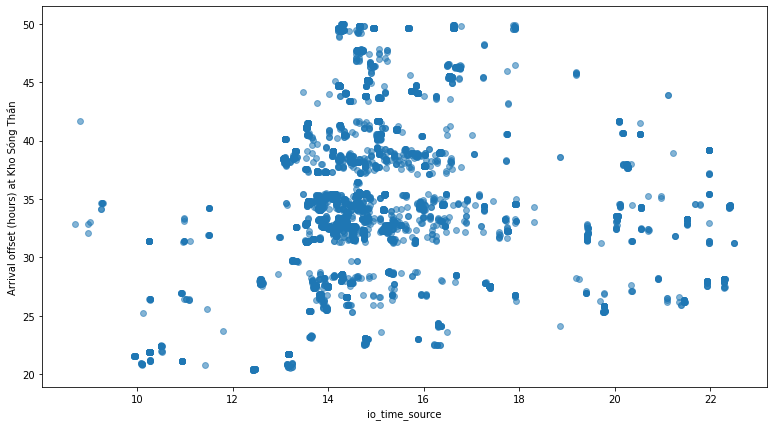

In [774]:
## Vẽ tại kho Đồng Tháp
X_data = bill_full_subset[bill_full_subset.warehouse_source=='Kho Đồng Tháp'].copy() #
X_data = X_data[X_data.io_status_source=='OUT'].copy()
plt.figure(figsize=(13, 7))
plt.scatter(
    X_data["io_time_source"],
    X_data['arrival_offset_hours'],
    s=35,
    alpha=0.55,
)
plt.xlabel("io_time_source")
plt.ylabel("Arrival offset (hours) at " + destination)
plt.show()

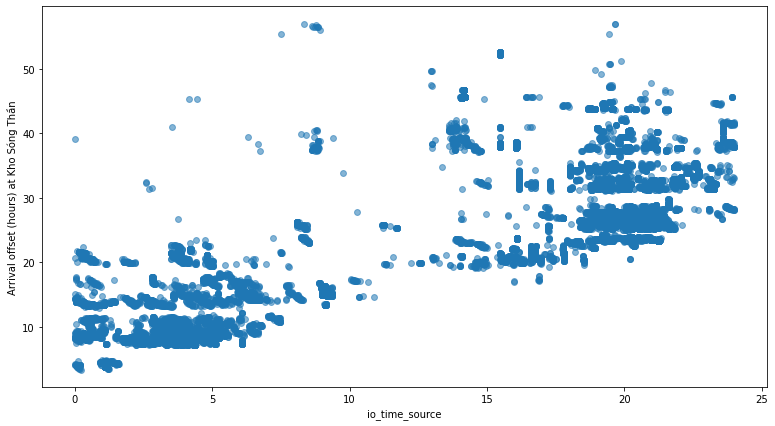

In [775]:
## Vẽ tại kho Long An
X_data = bill_full_subset[bill_full_subset.warehouse_source=='Kho Long An'].copy() #Kho Đồng Tháp
X_data = X_data[X_data.io_status_source=='OUT'].copy()
plt.figure(figsize=(13, 7))
plt.scatter(
    X_data["io_time_source"],
    X_data['arrival_offset_hours'],
    s=35,
    alpha=0.55,
)
plt.xlabel("io_time_source")
plt.ylabel("Arrival offset (hours) at " + destination)
plt.show()